In [125]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [126]:
np.random.seed(42)

In [127]:
def r_squared(y, y_hat):
    ss_res = np.sum((y - y_hat)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res/ss_tot

Data

In [128]:
x = np.linspace(1, 10, 20)
y = 2.5*x + 1.8 + np.random.normal(0,1.5, 20)

In [129]:
x

array([ 1.        ,  1.47368421,  1.94736842,  2.42105263,  2.89473684,
        3.36842105,  3.84210526,  4.31578947,  4.78947368,  5.26315789,
        5.73684211,  6.21052632,  6.68421053,  7.15789474,  7.63157895,
        8.10526316,  8.57894737,  9.05263158,  9.52631579, 10.        ])

In [130]:
y

array([ 5.04507123,  5.27681407,  7.63995386, 10.13717636,  8.68561204,
        9.8698472 , 13.77408238, 13.74062578, 13.06947263, 15.7717348 ,
       15.44697872, 16.62772116, 18.87346972, 16.82481648, 18.29157062,
       21.2197266 , 21.72812174, 24.90294995, 24.25375336, 24.68154445])

1.Linear Fit - Normal equations

In [131]:
n = len(x)
a = (n*np.sum(x*y) - np.sum(x)*np.sum(y)) / (n*np.sum(x**2) - np.sum(x)**2)
b = (np.sum(y) - a*np.sum(x)) / n
print(f'Linear: y = {a:.4f}x + {b:.4f}')
y_lin = a*x + b
print(f'R² = {r_squared(y, y_lin):.4f}')

Linear: y = 2.1847x + 3.2771
R² = 0.9667


2. Quadratic Fit

In [132]:
x2 = np.linspace(-3, 3, 25)
y2 = 1.5*x2**15 - 2*x2 + 3 + np.random.normal(0,1,25)
c2 = np.polyfit(x2, y2, 2)
print(f'Quadratic: y = {c2[0]:.4f}x² + {c2[1]:.4f}x + {c2[2]:.4f}')
print(f'R² = {r_squared(y2, np.polyval(c2,x2)):.4f}')

Quadratic: y = 0.0108x² + 2089066.4589x + 2.7127
R² = 0.3551


3. EXPONENTIAL FIT: Linearize ln(y) = ln(a) + bx

In [133]:
x3 = np.linspace(0, 3, 20)
y3 = 2.0*np.exp(0.8*x3) + np.random.normal(0, 0.5, 20)
log_y3  = np.log(y3)
ce = np.polyfit(x3, log_y3, 1)
a_e, b_e = np.exp(ce[1]), ce[0]
print(f'Exponential: y = {a_e:.4f}•e^({b_e:.4f}x)')
y_exp = a_e * np.exp(b_e * x3)
print(f'R² = {r_squared(y3, y_exp):.4f}')

Exponential: y = 1.8999•e^(0.8231x)
R² = 0.9943


4. POWER FIT: Linearize ln(y) = ln(a) + b•ln(x)

In [134]:
x4 = np.linspace(0.5, 5, 20)
y4 = 1.5*x4**2.3 + np.random.normal(0, 0.5, 20)
cp = np.polyfit(np.log(x4), np.log(y4), 1)
a_p, b_p = np.exp(cp[1]), cp[0]
print(f'Power: y = {a_p:.4f}•x^{b_p:.4f}')
y_pow = a_p * x4**b_p
print(f'R² = {r_squared(y4, y_pow):.4f}')

Power: y = 2.0010•x^2.0478
R² = 0.9831


VISUALIZATION

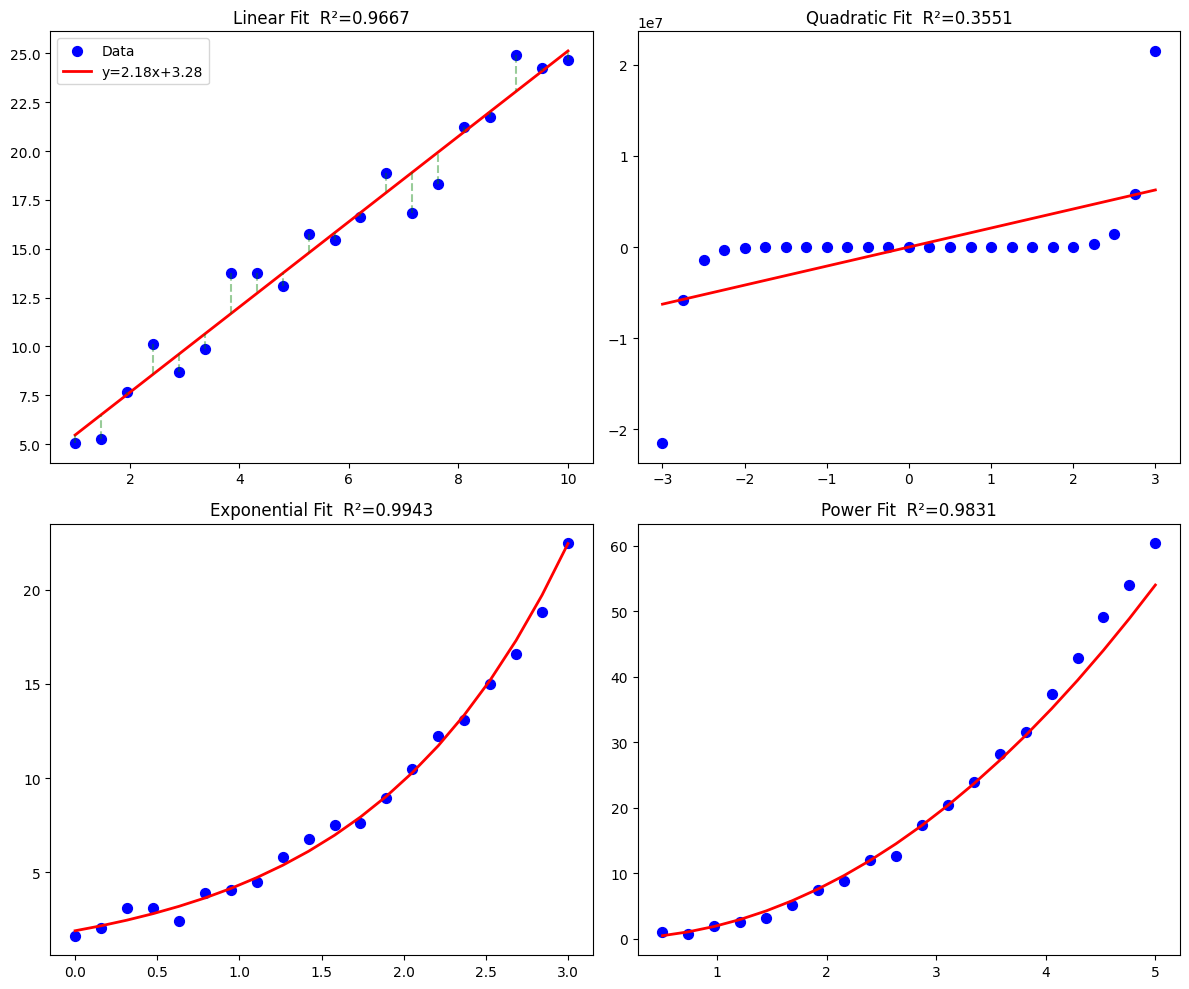

In [135]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Linear
xf = np.linspace(x.min(), x.max(), 200)
axes[0,0].scatter(x, y, color='blue', s=50, label='Data')
axes[0,0].plot(xf, a*xf+b, 'r-', lw=2, label=f'y={a:.2f}x+{b:.2f}')
for xi,yi,yp in zip(x,y,y_lin):
    axes[0,0].plot([xi,xi],[yi,yp],'g--',alpha=0.4)
axes[0,0].set_title(f'Linear Fit  R²={r_squared(y,y_lin):.4f}')
axes[0,0].legend()

# Quadratic
xf2 = np.linspace(x2.min(), x2.max(), 200)
axes[0,1].scatter(x2, y2, color='blue', s=50)
axes[0,1].plot(xf2, np.polyval(c2,xf2), 'r-', lw=2)
axes[0,1].set_title(f'Quadratic Fit  R²={r_squared(y2,np.polyval(c2,x2)):.4f}')

# Exponential
axes[1,0].scatter(x3, y3, color='blue', s=50)
axes[1,0].plot(x3, y_exp, 'r-', lw=2)
axes[1,0].set_title(f'Exponential Fit  R²={r_squared(y3,y_exp):.4f}')

# Power
axes[1,1].scatter(x4, y4, color='blue', s=50)
axes[1,1].plot(x4, y_pow, 'r-', lw=2)
axes[1,1].set_title(f'Power Fit  R²={r_squared(y4,y_pow):.4f}')

plt.tight_layout(); plt.show()